# Classification d’images avec CNN 
**Objectif :** réaliser les étapes du TP, mesurer un CNN de référence, puis tester une amélioration par transfert d’apprentissage avec MobileNetV2 pré-entraîné sur ImageNet.


Le CNN de référence respecte l’architecture demandée dans les consignes. Le modèle amélioré utilise augmentation légère et transfert d’apprentissage. Il faut comparer les deux sur les mêmes ensembles et retenir le choix à partir de la validation.

## 1. Imports et reproductibilité

In [ ]:
import os, random, time, pathlib
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix

SEED = 123
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
print("TensorFlow :", tf.__version__)
print("GPU(s) :", tf.config.list_physical_devices("GPU"))


TensorFlow : 2.21.0
GPU(s) : []


## 2. Téléchargement et repérage du jeu de données

In [ ]:
# KaggleHub télécharge le jeu public Intel Image Classification.
# Dans Colab, cette installation ne se fait qu’une seule fois si nécessaire.
try:
    import kagglehub
except ImportError:
    %pip -q install kagglehub
    import kagglehub

ROOT = pathlib.Path(kagglehub.dataset_download("puneet6060/intel-image-classification"))
print("Dossier téléchargé :", ROOT)

EXPECTED_CLASSES = {"buildings", "forest", "glacier", "mountain", "sea", "street"}

def find_split_dir(root, split_name):
    """Trouve le dossier seg_train ou seg_test contenant directement les classes."""
    candidates = [p for p in root.rglob(split_name) if p.is_dir()]
    for candidate in candidates:
        direct_subdirs = {p.name for p in candidate.iterdir() if p.is_dir()}
        if EXPECTED_CLASSES.issubset(direct_subdirs):
            return candidate
    raise FileNotFoundError(f"Impossible de trouver {split_name} avec les six dossiers de classes sous {root}")

TRAIN_DIR = find_split_dir(ROOT, "seg_train")
TEST_DIR = find_split_dir(ROOT, "seg_test")
print("Train :", TRAIN_DIR)
print("Test  :", TEST_DIR)


Using Colab cache for faster access to the 'intel-image-classification' dataset.
Dossier téléchargé : /kaggle/input/intel-image-classification
Train : /kaggle/input/intel-image-classification/seg_train/seg_train
Test  : /kaggle/input/intel-image-classification/seg_test/seg_test


## 3. Exploration du jeu de données

In [ ]:
class_names = sorted(p.name for p in TRAIN_DIR.iterdir() if p.is_dir())
assert set(class_names) == EXPECTED_CLASSES, f"Classes inattendues : {class_names}"

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp"}
def count_images(split_dir):
    return {name: sum(1 for p in (split_dir / name).iterdir()
                      if p.is_file() and p.suffix.lower() in IMAGE_EXTS)
            for name in class_names}

train_counts = count_images(TRAIN_DIR)
test_counts = count_images(TEST_DIR)
print("Classes :", class_names)
print("Images train :", sum(train_counts.values()), train_counts)
print("Images test  :", sum(test_counts.values()), test_counts)
print("Total étiqueté :", sum(train_counts.values()) + sum(test_counts.values()))


Classes : ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Images train : 14034 {'buildings': 2191, 'forest': 2271, 'glacier': 2404, 'mountain': 2512, 'sea': 2274, 'street': 2382}
Images test  : 3000 {'buildings': 437, 'forest': 474, 'glacier': 553, 'mountain': 525, 'sea': 510, 'street': 501}
Total étiqueté : 17034


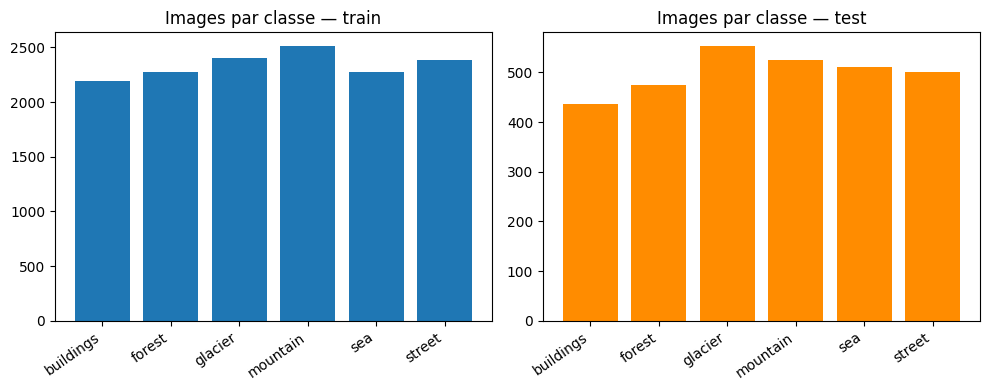

In [ ]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.bar(train_counts.keys(), train_counts.values())
plt.title("Images par classe — train")
plt.xticks(rotation=35, ha="right")
plt.subplot(1, 2, 2)
plt.bar(test_counts.keys(), test_counts.values(), color="darkorange")
plt.title("Images par classe — test")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


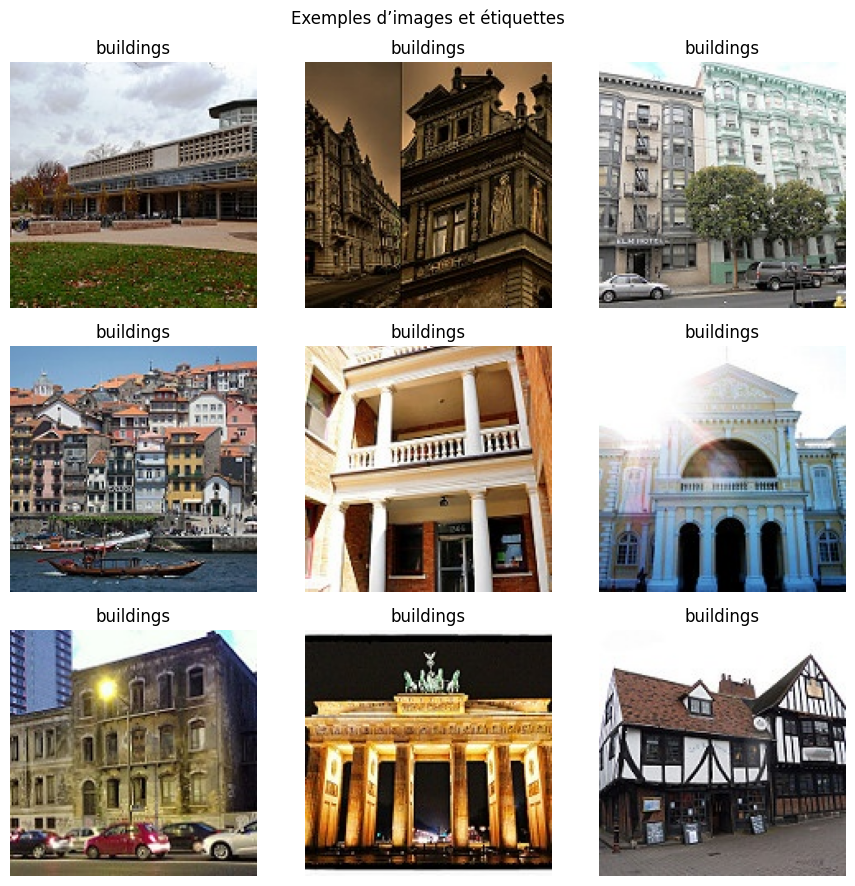

Exemple — format : JPEG | mode : RGB | dimensions : (150, 150)


In [ ]:
from PIL import Image
sample_paths = [p for c in class_names for p in (TRAIN_DIR / c).iterdir()
                if p.is_file() and p.suffix.lower() in IMAGE_EXTS][:9]
fig, axes = plt.subplots(3, 3, figsize=(9, 9))
for ax, path in zip(axes.flat, sample_paths):
    with Image.open(path) as im:
        ax.imshow(im.convert("RGB"))
    ax.set_title(path.parent.name)
    ax.axis("off")
plt.suptitle("Exemples d’images et étiquettes")
plt.tight_layout()
plt.show()

with Image.open(sample_paths[0]) as im:
    print("Exemple — format :", im.format, "| mode :", im.mode, "| dimensions :", im.size)


**Analyse rapide.** Le jeu comporte six classes de paysages. Des confusions sont plausibles entre *glacier* et *mountain*, ou entre *buildings* et *street*. Les images sont classées dans des dossiers, donc Keras utilise le nom du dossier comme étiquette. Les nombres ci-dessus permettent de vérifier la répartition réelle.

## 4. Prétraitement et découpage train / validation / test

In [ ]:
IMG_SIZE = (150, 150)  # taille demandée dans les consignes
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

train_raw = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, validation_split=0.2, subset="training", seed=SEED,
    image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode="int", shuffle=True
)
val_raw = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, validation_split=0.2, subset="validation", seed=SEED,
    image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode="int", shuffle=False
)
# shuffle=False rend l’ordre des exemples stable pour les matrices de confusion.
test_dataset = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=False
)

class_names = train_raw.class_names
assert val_raw.class_names == class_names and test_dataset.class_names == class_names
train_dataset = train_raw.prefetch(AUTOTUNE)
validation_dataset = val_raw.prefetch(AUTOTUNE)
test_dataset = test_dataset.prefetch(AUTOTUNE)
NUM_CLASSES = len(class_names)
print("Ordre des classes :", class_names)
print("Nombre de classes :", NUM_CLASSES)


Found 14034 files belonging to 6 classes.
Using 11228 files for training.
Found 14034 files belonging to 6 classes.
Using 2806 files for validation.
Found 3000 files belonging to 6 classes.
Ordre des classes : ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Nombre de classes : 6


### Normalisation
Les pixels bruts sont compris entre 0 et 255. Pour le CNN de référence, `Rescaling(1./255)` les ramène entre 0 et 1, ce qui aide l’optimisation à travailler avec des valeurs d’entrée plus régulières. MobileNetV2 utilise son propre prétraitement vers l’intervalle attendu par ses poids ImageNet.

## 5. CNN initial conforme au TP

In [ ]:
def build_baseline_cnn():
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(*IMG_SIZE, 3)),
        tf.keras.layers.Rescaling(1./255),
        tf.keras.layers.Conv2D(32, 3, activation="relu"),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Conv2D(64, 3, activation="relu"),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Conv2D(128, 3, activation="relu"),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.GlobalAveragePooling2D(),
        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")
    ], name="cnn_initial")

baseline = build_baseline_cnn()
baseline.summary()


Model: "cnn_initial"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,894 (398.02 KB)

 Trainable params: 101,894 (398.02 KB)

 Non-trainable params: 0 (0.00 B)

### Entraînement du CNN initial
On conserve le meilleur poids selon la perte de validation. L’arrêt anticipé évite de continuer longtemps quand la validation ne progresse plus.

In [ ]:
def make_callbacks(prefix):
    return [
        tf.keras.callbacks.ModelCheckpoint(
            filepath=f"{prefix}_best.keras", monitor="val_loss",
            save_best_only=True, verbose=1
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=5, restore_best_weights=True, verbose=1
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1
        )
    ]

def compile_classifier(model, learning_rate=1e-3):
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"]
    )

compile_classifier(baseline)
start = time.time()
history_baseline = baseline.fit(
    train_dataset, validation_data=validation_dataset,
    epochs=30, callbacks=make_callbacks("cnn_initial"), verbose=1
)
time_baseline = time.time() - start
print(f"Durée CNN initial : {time_baseline/60:.1f} min")


Epoch 1/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.3998 - loss: 1.4131
Epoch 1: val_loss improved from None to 0.98744, saving model to cnn_initial_best.keras

Epoch 1: finished saving model to cnn_initial_best.keras
351/351 ━━━━━━━━━━━━━━━━━━━━ 982s 3s/step - accuracy: 0.4669 - loss: 1.2591 - val_accuracy: 0.5852 - val_loss: 0.9874 - learning_rate: 0.0010
Epoch 2/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.5757 - loss: 1.0260
Epoch 2: val_loss improved from 0.98744 to 0.72513, saving model to cnn_initial_best.keras

Epoch 2: finished saving model to cnn_initial_best.keras
351/351 ━━━━━━━━━━━━━━━━━━━━ 974s 3s/step - accuracy: 0.5981 - loss: 0.9823 - val_accuracy: 0.7716 - val_loss: 0.7251 - learning_rate: 0.0010
Epoch 3/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.6431 - loss: 0.8907
Epoch 3: val_loss did not improve from 0.72513
351/351 ━━━━━━━━━━━━━━━━━━━━ 1001s 3s/step - accuracy: 0.6522 - loss: 0.8685 - val_accuracy: 0.7202 - val_loss: 0.8312 

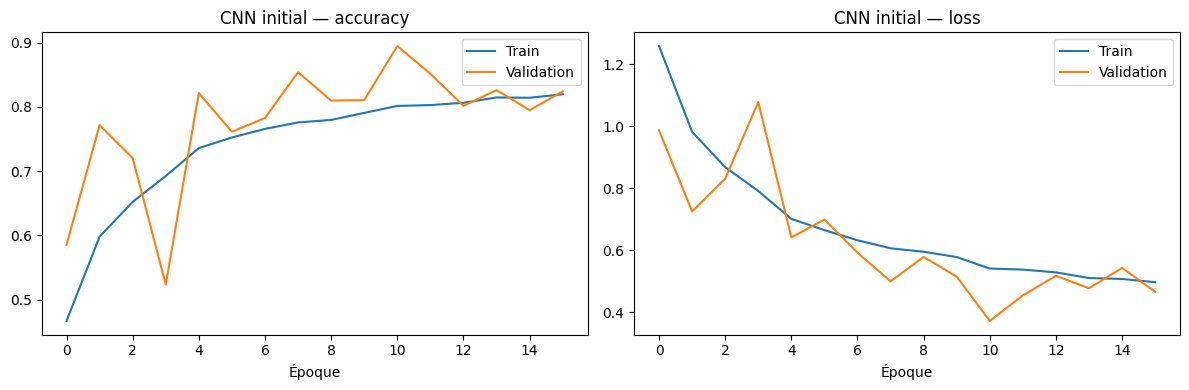

In [ ]:
def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history.history["accuracy"], label="Train")
    axes[0].plot(history.history["val_accuracy"], label="Validation")
    axes[0].set_title(title + " — accuracy")
    axes[0].set_xlabel("Époque")
    axes[0].legend()
    axes[1].plot(history.history["loss"], label="Train")
    axes[1].plot(history.history["val_loss"], label="Validation")
    axes[1].set_title(title + " — loss")
    axes[1].set_xlabel("Époque")
    axes[1].legend()
    plt.tight_layout()
    plt.show()

plot_history(history_baseline, "CNN initial")


## 6. Modèle amélioré : MobileNetV2 pré-entraîné

Un CNN entraîné depuis zéro peut avoir besoin de beaucoup d’images et d’époques. MobileNetV2 possède déjà des filtres visuels appris sur ImageNet. On gèle d’abord sa base et on entraîne une petite tête de classification, puis on dégèle seulement les dernières couches avec un taux d’apprentissage faible. L’augmentation légère apporte de la variété aux images d’entraînement. Cette approche est une piste plus solide, mais le résultat doit être mesuré sur la validation et le test.

In [ ]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.08),
], name="augmentation_legere")

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(*IMG_SIZE, 3), include_top=False, weights="imagenet"
)
base_model.trainable = False

inputs = tf.keras.Input(shape=(*IMG_SIZE, 3))
x = data_augmentation(inputs)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.25)(x)
outputs = tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")(x)
transfer_model = tf.keras.Model(inputs, outputs, name="mobilenetv2_transfer")
transfer_model.summary()


/tmp/ipykernel_79677/1548625140.py:7: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = tf.keras.applications.MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "mobilenetv2_transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation_legere             │ (None, 150, 150, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

### Phase A — entraînement de la tête de classification

Epoch 1/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 0s 683ms/step - accuracy: 0.7384 - loss: 0.7204
Epoch 1: val_loss improved from None to 0.36723, saving model to mobilenet_tete_best.keras

Epoch 1: finished saving model to mobilenet_tete_best.keras
351/351 ━━━━━━━━━━━━━━━━━━━━ 330s 925ms/step - accuracy: 0.8172 - loss: 0.5090 - val_accuracy: 0.8585 - val_loss: 0.3672 - learning_rate: 0.0010
Epoch 2/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 0s 678ms/step - accuracy: 0.8699 - loss: 0.3625
Epoch 2: val_loss improved from 0.36723 to 0.30827, saving model to mobilenet_tete_best.keras

Epoch 2: finished saving model to mobilenet_tete_best.keras
351/351 ━━━━━━━━━━━━━━━━━━━━ 321s 914ms/step - accuracy: 0.8725 - loss: 0.3556 - val_accuracy: 0.8885 - val_loss: 0.3083 - learning_rate: 0.0010
Epoch 3/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 0s 684ms/step - accuracy: 0.8846 - loss: 0.3319
Epoch 3: val_loss improved from 0.30827 to 0.25965, saving model to mobilenet_tete_best.keras

Epoch 3: finished saving model to mobilenet_

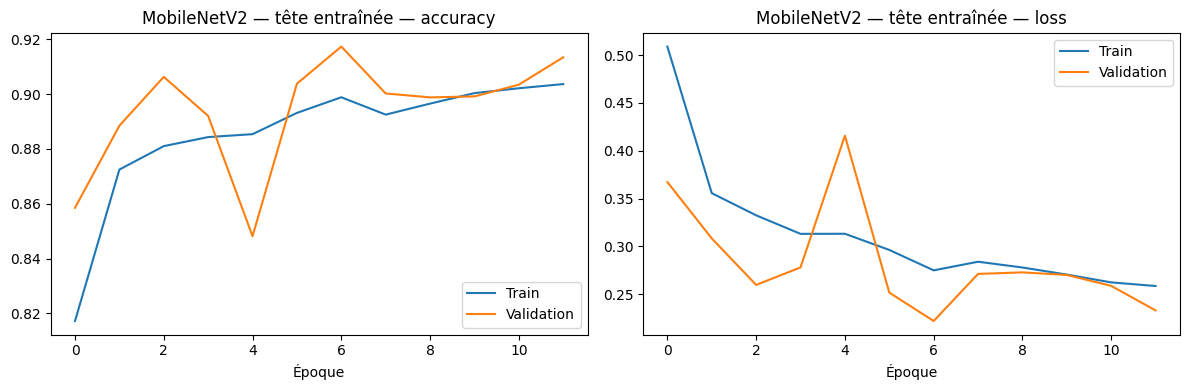

In [ ]:
compile_classifier(transfer_model, learning_rate=1e-3)
start = time.time()
history_transfer_head = transfer_model.fit(
    train_dataset, validation_data=validation_dataset,
    epochs=15, callbacks=make_callbacks("mobilenet_tete"), verbose=1
)
time_transfer_head = time.time() - start
plot_history(history_transfer_head, "MobileNetV2 — tête entraînée")


### Phase B — ajustement fin des dernières couches

Epoch 1/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 0s 874ms/step - accuracy: 0.9002 - loss: 0.2796
Epoch 1: val_loss improved from None to 0.18965, saving model to mobilenet_finetune_best.keras

Epoch 1: finished saving model to mobilenet_finetune_best.keras
351/351 ━━━━━━━━━━━━━━━━━━━━ 368s 1s/step - accuracy: 0.9028 - loss: 0.2706 - val_accuracy: 0.9301 - val_loss: 0.1896 - learning_rate: 1.0000e-05
Epoch 2/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 0s 858ms/step - accuracy: 0.9103 - loss: 0.2511
Epoch 2: val_loss improved from 0.18965 to 0.18173, saving model to mobilenet_finetune_best.keras

Epoch 2: finished saving model to mobilenet_finetune_best.keras
351/351 ━━━━━━━━━━━━━━━━━━━━ 350s 997ms/step - accuracy: 0.9106 - loss: 0.2455 - val_accuracy: 0.9337 - val_loss: 0.1817 - learning_rate: 1.0000e-05
Epoch 3/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 0s 866ms/step - accuracy: 0.9082 - loss: 0.2454
Epoch 3: val_loss improved from 0.18173 to 0.16026, saving model to mobilenet_finetune_best.keras

Epoch 3: finished s

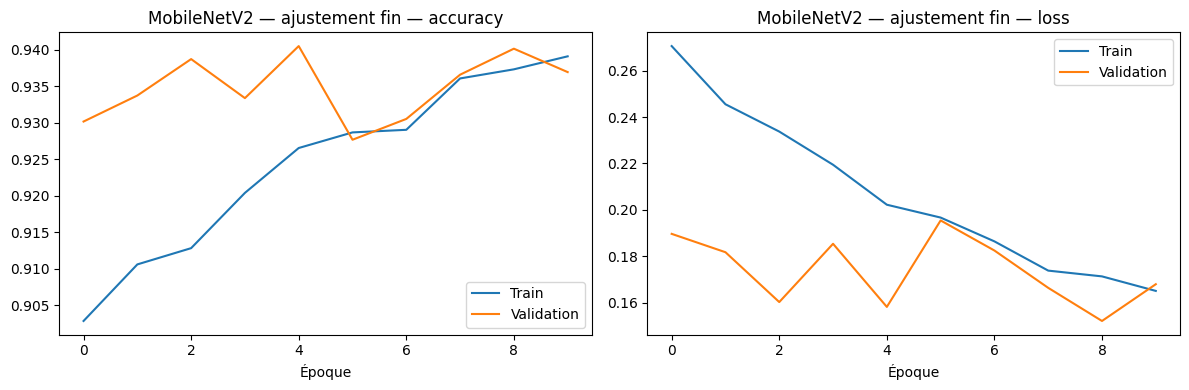

In [ ]:
# On débloque uniquement les 30 dernières couches pour limiter le surapprentissage.
base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False
# Les BatchNorm restent gelées, plus stables avec un petit jeu de données.
compile_classifier(transfer_model, learning_rate=1e-5)
start = time.time()
history_finetune = transfer_model.fit(
    train_dataset, validation_data=validation_dataset,
    epochs=10, callbacks=make_callbacks("mobilenet_finetune"), verbose=1
)
time_finetune = time.time() - start
plot_history(history_finetune, "MobileNetV2 — ajustement fin")


In [ ]:
# Le choix du modèle final repose sur la validation, avant d’interpréter les scores test.
val_loss_baseline, val_acc_baseline = baseline.evaluate(validation_dataset, verbose=0)
val_loss_transfer, val_acc_transfer = transfer_model.evaluate(validation_dataset, verbose=0)
print(f"CNN initial — val loss : {val_loss_baseline:.4f} | val accuracy : {val_acc_baseline:.4f}")
print(f"MobileNetV2   — val loss : {val_loss_transfer:.4f} | val accuracy : {val_acc_transfer:.4f}")
final_model = transfer_model if val_acc_transfer >= val_acc_baseline else baseline
final_model_name = "MobileNetV2" if final_model is transfer_model else "CNN initial"
print("Modèle retenu selon la validation :", final_model_name)


CNN initial — val loss : 0.3721 | val accuracy : 0.8945
MobileNetV2   — val loss : 0.1521 | val accuracy : 0.9401
Modèle retenu selon la validation : MobileNetV2


## 7. Choix selon la validation, puis évaluation finale


## 8. Évaluation comparative et rapports

Les modèles sont comparés avec le même jeu de test. Pour les matrices de confusion, les étiquettes réelles et les prédictions sont collectées dans un seul passage, dans le même ordre. On ne choisit pas un modèle en fonction du test : le choix se fait d’abord à l’aide de la validation.

CNN initial — test loss : 0.5622 | test accuracy : 0.7903
              precision    recall  f1-score   support

   buildings      0.820     0.634     0.715       437
      forest      0.958     0.920     0.939       474
     glacier      0.754     0.772     0.763       553
    mountain      0.794     0.697     0.742       525
         sea      0.758     0.839     0.796       510
      street      0.711     0.872     0.783       501

    accuracy                          0.790      3000
   macro avg      0.799     0.789     0.790      3000
weighted avg      0.796     0.790     0.789      3000



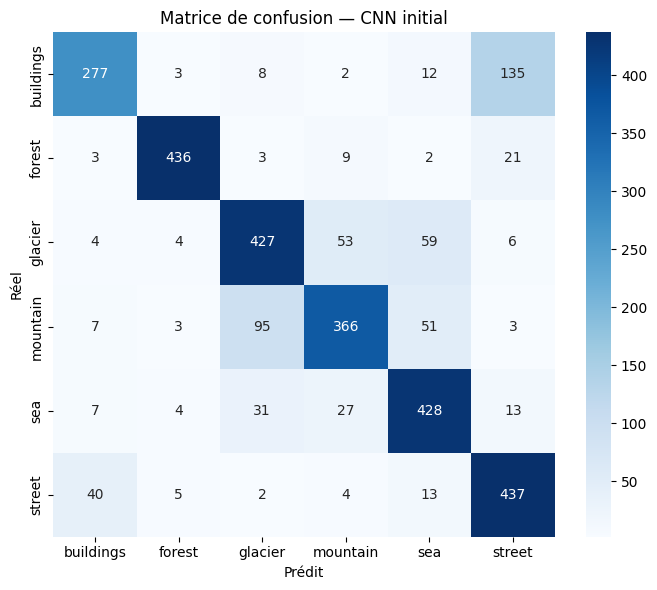

MobileNetV2 — test loss : 0.2135 | test accuracy : 0.9177
              precision    recall  f1-score   support

   buildings      0.894     0.950     0.921       437
      forest      0.991     0.983     0.987       474
     glacier      0.875     0.852     0.863       553
    mountain      0.877     0.853     0.865       525
         sea      0.933     0.978     0.955       510
      street      0.942     0.906     0.924       501

    accuracy                          0.918      3000
   macro avg      0.919     0.920     0.919      3000
weighted avg      0.918     0.918     0.917      3000



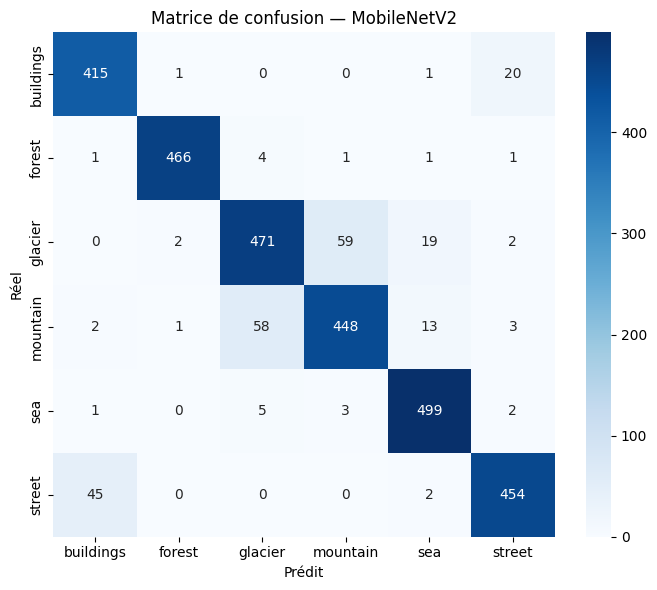

In [ ]:
def evaluate_and_report(model, name):
    loss, accuracy = model.evaluate(test_dataset, verbose=0)
    y_true, y_pred = [], []
    for images, labels in test_dataset:
        probabilities = model.predict(images, verbose=0)
        y_true.extend(labels.numpy().tolist())
        y_pred.extend(np.argmax(probabilities, axis=1).tolist())
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    print(f"{name} — test loss : {loss:.4f} | test accuracy : {accuracy:.4f}")
    print(classification_report(y_true, y_pred, target_names=class_names, digits=3))
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(7, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names)
    plt.xlabel("Prédit")
    plt.ylabel("Réel")
    plt.title(f"Matrice de confusion — {name}")
    plt.tight_layout()
    plt.show()
    return {"Modèle": name, "Test loss": loss, "Test accuracy": accuracy}, y_true, y_pred

result_baseline, y_true, pred_baseline = evaluate_and_report(baseline, "CNN initial")
result_transfer, y_true_transfer, pred_transfer = evaluate_and_report(transfer_model, "MobileNetV2")
assert np.array_equal(y_true, y_true_transfer), "L’ordre du test doit rester identique."


CNN initial      | loss=0.5622 | accuracy=0.7903
MobileNetV2      | loss=0.2135 | accuracy=0.9177


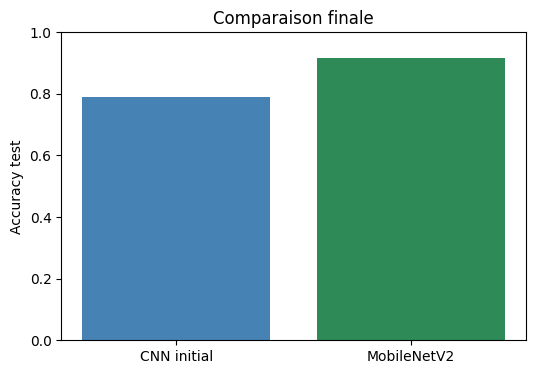

In [ ]:
# Comparaison des scores de test ; la sélection du modèle final doit rester fondée sur la validation.
comparison = [result_baseline, result_transfer]
for row in comparison:
    print(f"{row['Modèle']:16s} | loss={row['Test loss']:.4f} | accuracy={row['Test accuracy']:.4f}")

plt.figure(figsize=(6, 4))
plt.bar([r["Modèle"] for r in comparison], [r["Test accuracy"] for r in comparison],
        color=["steelblue", "seagreen"])
plt.ylim(0, 1)
plt.ylabel("Accuracy test")
plt.title("Comparaison finale")
plt.show()


In [ ]:
# Comparaison des critères demandés dans le TP.
def best_history_value(history, key, reducer=max):
    return float(reducer(history.history[key]))

comparison_table = pd.DataFrame([
    {
        "Modèle": "CNN initial",
        "Architecture": "Conv32-64-128 + GAP + Dense64",
        "Paramètres": baseline.count_params(),
        "Val accuracy max": best_history_value(history_baseline, "val_accuracy"),
        "Val loss min": best_history_value(history_baseline, "val_loss", min),
        "Test accuracy": result_baseline["Test accuracy"],
        "Erreurs test": int(np.sum(y_true != pred_baseline)),
        "Temps entraînement (min)": time_baseline / 60,
    },
    {
        "Modèle": "MobileNetV2",
        "Architecture": "MobileNetV2 pré-entraîné + augmentation + fine-tuning",
        "Paramètres": transfer_model.count_params(),
        "Val accuracy max": max(
            best_history_value(history_transfer_head, "val_accuracy"),
            best_history_value(history_finetune, "val_accuracy")
        ),
        "Val loss min": min(
            best_history_value(history_transfer_head, "val_loss", min),
            best_history_value(history_finetune, "val_loss", min)
        ),
        "Test accuracy": result_transfer["Test accuracy"],
        "Erreurs test": int(np.sum(y_true_transfer != pred_transfer)),
        "Temps entraînement (min)": (time_transfer_head + time_finetune) / 60,
    }
])
print(comparison_table.to_string(index=False, float_format=lambda x: f"{x:.4f}"))


     Modèle                                          Architecture  Paramètres  Val accuracy max  Val loss min  Test accuracy  Erreurs test  Temps entraînement (min)
CNN initial                         Conv32-64-128 + GAP + Dense64      101894            0.8945        0.3721         0.7903           629                  204.3811
MobileNetV2 MobileNetV2 pré-entraîné + augmentation + fine-tuning     2265670            0.9405        0.1521         0.9177           247                  126.9467
